# Does Stacking Really Predict Heart Disease with 98.5% Accuracy?

**Reproducing a published model, finding duplicate-record leakage, and measuring honest performance**

A 2024 paper [1] reports that a stacking ensemble predicts heart disease with **98.53% accuracy** on a popular Kaggle dataset of 1,025 patients. This notebook:

1. **Reproduces** the paper's setup and results
2. **Checks the data**, and finds that the 1,025 rows contain only **302 unique patients**, so a random train/test split puts almost every test patient in the training data too
3. **Re-evaluates every model honestly** on the unique patients, with repeated cross-validation
4. **Looks at the clinically important trade-off:** how many heart disease cases a model misses

[1] M. Bhagat, A. Sharma and P. Agarwal, "An efficient stacking-based ensemble technique for early heart attack prediction," *Multimedia Tools and Applications*, 2024, doi: 10.1007/s11042-024-19293-7.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, matthews_corrcoef, precision_score,
                             recall_score, roc_auc_score, confusion_matrix)
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict,
                                     cross_validate, train_test_split)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

RS = 42
NUMERIC = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
BINARY = ["sex", "fbs", "exang"]
CATEGORICAL = ["cp", "restecg", "slope", "thal"]

# Chart styling
PAPER, LEAKY, HONEST = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
})
IMG = "images"

## 2. The data

In [2]:
df = pd.read_csv("data/heart.csv")
print(f"{len(df):,} rows x {df.shape[1]} columns, {df.isna().sum().sum()} missing values")
print(f"Target balance: {df['target'].value_counts().to_dict()}  (1 = heart disease)")
df.head()

1,025 rows x 14 columns, 0 missing values
Target balance: {1: 526, 0: 499}  (1 = heart disease)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


Features: age, sex, chest pain type (`cp`), resting blood pressure (`trestbps`), cholesterol (`chol`), fasting blood sugar (`fbs`), resting ECG (`restecg`), max heart rate (`thalach`), exercise-induced angina (`exang`), ST depression (`oldpeak`), ST slope (`slope`), number of major vessels (`ca`) and thalassemia (`thal`).

### How many patients are really in the dataset?

In [3]:
unique = df.drop_duplicates()
copies = df.groupby(list(df.columns)).size()

print(f"Rows:            {len(df):,}")
print(f"Unique patients: {len(unique):,}")
print(f"Duplicate rows:  {len(df) - len(unique):,} ({(len(df) - len(unique)) / len(df):.0%} of the file)\n")
print("How many times each unique patient appears:")
print(copies.value_counts().sort_index().rename_axis("copies").rename("patients").to_string())

Rows:            1,025
Unique patients: 302
Duplicate rows:  723 (71% of the file)

How many times each unique patient appears:
copies
3    187
4    114
8      1


**Observations**
- The file has **1,025 rows but only 302 unique patients.** 723 rows (71%) are exact copies.
- Every patient appears at least 3 times: 187 appear 3 times, 114 appear 4 times, and one appears 8 times.
- 302 patients is about the size of the well-known Cleveland subset of the UCI Heart Disease data, so the file appears to be that subset copied several times, rather than four databases combined as the paper describes.
- **Why it matters:** with a random split, copies of the same patient land on both sides. The model is then tested on patients it has already memorised.

## 3. Reproducing the paper

The paper's setup, as described [1]:
- All 1,025 rows, split randomly into training and test sets. Its stacking confusion matrix (Fig. 5) adds up to 205 test patients, which is a **20% test split**.
- Numerical features scaled and categorical features one-hot encoded.
- Six base classifiers (Logistic Regression, Decision Tree, Random Forest, XGBoost, Naive Bayes, KNN), plus a **5-fold stacking ensemble** of all six.

**Assumptions where the paper gives no details:**
- Default hyperparameters for every model, since none are reported.
- Logistic Regression as the stacking meta-classifier, since the paper names it as a typical choice.
- A stratified split with `random_state=42`. The paper's random seed isn't given, so individual numbers will differ a little.
- All preprocessing happens inside a pipeline fitted on training data only.

In [4]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC),
        ("bin", "passthrough", BINARY),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
    ])

def base_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=2000),
        "Decision Tree": DecisionTreeClassifier(random_state=RS),
        "Random Forest": RandomForestClassifier(random_state=RS),
        "XGBoost": XGBClassifier(eval_metric="logloss", random_state=RS),
        "Naive Bayes": GaussianNB(),
        "KNN": KNeighborsClassifier(),
    }

def all_pipelines():
    pipes = {name: Pipeline([("prep", make_preprocessor()), ("clf", m)]) for name, m in base_models().items()}
    stack = StackingClassifier(
        estimators=[(n.lower().replace(" ", "_"), m) for n, m in base_models().items()],
        final_estimator=LogisticRegression(max_iter=2000), cv=5)
    pipes["Stacking (paper)"] = Pipeline([("prep", make_preprocessor()), ("clf", stack)])
    return pipes

def scores(y_true, y_pred, y_prob):
    return {"Accuracy": accuracy_score(y_true, y_pred), "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred), "F1": f1_score(y_true, y_pred),
            "AUC": roc_auc_score(y_true, y_prob)}

X, y = df.drop(columns="target"), df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)

leaky = {}
for name, pipe in all_pipelines().items():
    pipe.fit(X_train, y_train)
    leaky[name] = scores(y_test, pipe.predict(X_test), pipe.predict_proba(X_test)[:, 1])
leaky = pd.DataFrame(leaky).T
leaky.round(4)

,Accuracy,Precision,Recall,F1,AUC
Logistic Regression,0.8585,0.8220,0.9238,0.8700,0.9255
Decision Tree,0.9854,1.0000,0.9714,0.9855,0.9857
Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000
XGBoost,1.0000,1.0000,1.0000,1.0000,1.0000
Naive Bayes,0.8195,0.8148,0.8381,0.8263,0.8750
KNN,0.8488,0.8426,0.8667,0.8545,0.9547
Stacking (paper),1.0000,1.0000,1.0000,1.0000,1.0000


### Comparison with the paper (Table 11)

In [5]:
paper = pd.DataFrame({
    "Accuracy":  [0.8439, 0.9268, 0.9268, 0.9073, 0.8439, 0.8585, 0.9853],
    "Precision": [0.8196, 0.9702, 0.9130, 0.9174, 0.8250, 0.8648, 1.0000],
    "Recall":    [0.9090, 0.8909, 0.9545, 0.9090, 0.9000, 0.8727, 0.9727],
    "F1":        [0.8620, 0.9289, 0.9333, 0.9132, 0.8608, 0.8687, 0.9861],
    "AUC":       [0.9204, 0.9702, 0.9734, 0.9830, 0.9185, 0.9304, 0.9880],
}, index=["Logistic Regression", "Decision Tree", "Random Forest", "XGBoost", "Naive Bayes", "KNN", "Stacking (paper)"])

compare = pd.DataFrame({"Paper accuracy": paper["Accuracy"], "Reproduced accuracy": leaky["Accuracy"]})
compare["Difference"] = compare["Reproduced accuracy"] - compare["Paper accuracy"]
compare.round(4)

,Paper accuracy,Reproduced accuracy,Difference
Logistic Regression,0.8439,0.8585,0.0146
Decision Tree,0.9268,0.9854,0.0586
Random Forest,0.9268,1.0000,0.0732
XGBoost,0.9073,1.0000,0.0927
Naive Bayes,0.8439,0.8195,-0.0244
KNN,0.8585,0.8488,-0.0097
Stacking (paper),0.9853,1.0000,0.0147


### Why are the scores so high? Checking the test set

In [6]:
train_rows = set(map(tuple, pd.concat([X_train, y_train], axis=1).values))
seen = np.array([tuple(r) in train_rows for r in pd.concat([X_test, y_test], axis=1).values])
print(f"Test patients that also appear in the training set: {seen.sum()} of {len(seen)} ({seen.mean():.0%})")

Test patients that also appear in the training set: 202 of 205 (99%)


### Inconsistencies in the paper's reported metrics
Two details in the paper's tables don't add up, which makes its numbers harder to trust:

In [7]:
# The paper's stacking confusion matrix (Fig. 5): 95 true negatives, 0 false positives, 3 false negatives, 107 true positives
tn, fp, fn, tp = 95, 0, 3, 107
y_true_fig5 = np.array([0] * (tn + fp) + [1] * (fn + tp))
y_pred_fig5 = np.array([0] * tn + [1] * fp + [0] * fn + [1] * tp)
print(f"MCC reported in Table 12:           1.0000")
print(f"MCC implied by its confusion matrix: {matthews_corrcoef(y_true_fig5, y_pred_fig5):.4f}")
print(f"Specificity implied (TN / (TN+FP)):  {tn / (tn + fp):.4f}  (reported: 0.9861)")

MCC reported in Table 12:           1.0000
MCC implied by its confusion matrix: 0.9711
Specificity implied (TN / (TN+FP)):  1.0000  (reported: 0.9861)


**Observations**
- **The reproduction matches the paper's pattern:** the tree-based models and stacking come out near the top, with Logistic Regression, Naive Bayes and KNN lower.
- **The tree-based scores come out even higher than published.** Random Forest, XGBoost and stacking all hit exactly 100% here, against 90.7 to 98.5% in the paper. Differences in random seed and default settings can't produce a perfect score on their own.
- **The cause is leakage: 202 of the 205 test patients (99%) also appear in the training data.** Unpruned trees memorise every training patient, so they "predict" the test set perfectly. That's why the trees gain most from the leak, while Logistic Regression and Naive Bayes, which can't memorise individual rows, barely change.
- **The paper's own tables have internal errors.** Its stacking confusion matrix (3 misclassified patients) implies an MCC of 0.971, not the 1.0 reported. In Table 11, the MCC column is identical to the precision column for every model, and the specificity values match the F1 values. These look like copy errors.
- **Conclusion:** the paper's 98.53% isn't a measure of how well stacking predicts heart disease in new patients.

## 4. Honest evaluation on unique patients

To get a realistic estimate:
- **Use each patient once** (302 unique patients).
- **Use repeated stratified 5-fold cross-validation** (5 folds x 10 repeats = 50 train/test splits). With only about 60 patients per test fold, a single split is too noisy. Repeating it gives a mean and a spread.
- **Keep the same models and preprocessing**, so the only change is removing the leakage.

In [8]:
Xu, yu = unique.drop(columns="target"), unique["target"]
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RS)
metrics = {"Accuracy": "accuracy", "Precision": "precision", "Recall": "recall", "F1": "f1", "AUC": "roc_auc"}

honest_runs, honest = {}, {}
for name, pipe in all_pipelines().items():
    r = cross_validate(pipe, Xu, yu, cv=cv, scoring=metrics, n_jobs=-1)
    honest_runs[name] = r["test_Accuracy"]
    honest[name] = {m: r[f"test_{m}"].mean() for m in metrics} | {"Accuracy SD": r["test_Accuracy"].std()}
honest = pd.DataFrame(honest).T.sort_values("Accuracy", ascending=False)
honest.round(3)

,Accuracy,Precision,Recall,F1,AUC,Accuracy SD
Logistic Regression,0.831,0.827,0.876,0.849,0.906,0.034
Stacking (paper),0.828,0.831,0.862,0.844,0.902,0.034
Random Forest,0.824,0.831,0.853,0.840,0.902,0.034
KNN,0.822,0.833,0.845,0.837,0.876,0.046
XGBoost,0.801,0.811,0.830,0.818,0.880,0.040
Naive Bayes,0.756,0.784,0.809,0.778,0.865,0.089
Decision Tree,0.737,0.757,0.764,0.759,0.735,0.049


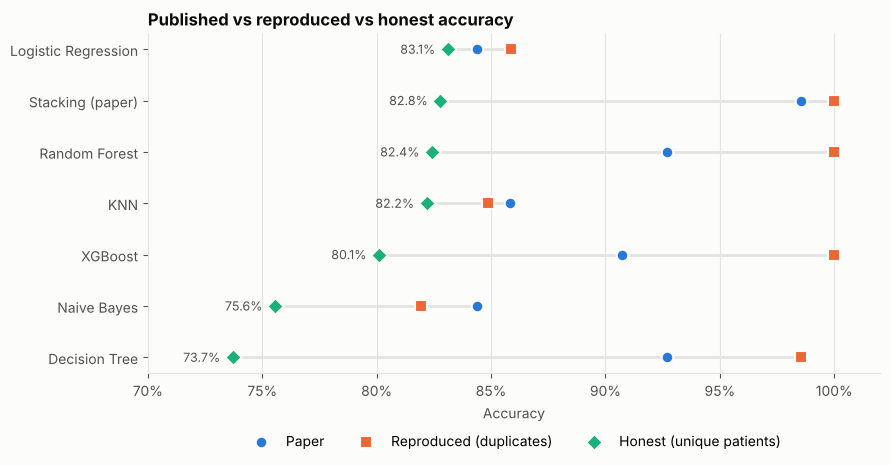

In [9]:
summary = pd.DataFrame({
    "Paper": paper["Accuracy"],
    "Reproduced (duplicates)": leaky["Accuracy"],
    "Honest (unique patients)": honest["Accuracy"],
}).loc[honest.index]

fig, ax = plt.subplots(figsize=(9, 4.8))
ypos = np.arange(len(summary))[::-1]
for col, colour, marker in [("Paper", PAPER, "o"), ("Reproduced (duplicates)", LEAKY, "s"), ("Honest (unique patients)", HONEST, "D")]:
    ax.scatter(summary[col], ypos, s=70, color=colour, marker=marker, edgecolor="#fcfcfb", linewidth=1.5, zorder=3, label=col)
for yi, (lo, hi) in zip(ypos, zip(summary.min(axis=1), summary.max(axis=1))):
    ax.hlines(yi, lo, hi, color=GRID, linewidth=2, zorder=1)
for yi, v in zip(ypos, summary["Honest (unique patients)"]):
    ax.annotate(f"{v:.1%}", (v, yi), xytext=(-9, 0), textcoords="offset points", ha="right", va="center", fontsize=9, color=INK2)
ax.set_yticks(ypos, summary.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Accuracy")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlim(0.7, 1.02)
ax.set_title("Published vs reproduced vs honest accuracy", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False)
plt.tight_layout()
plt.savefig(f"{IMG}/accuracy_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

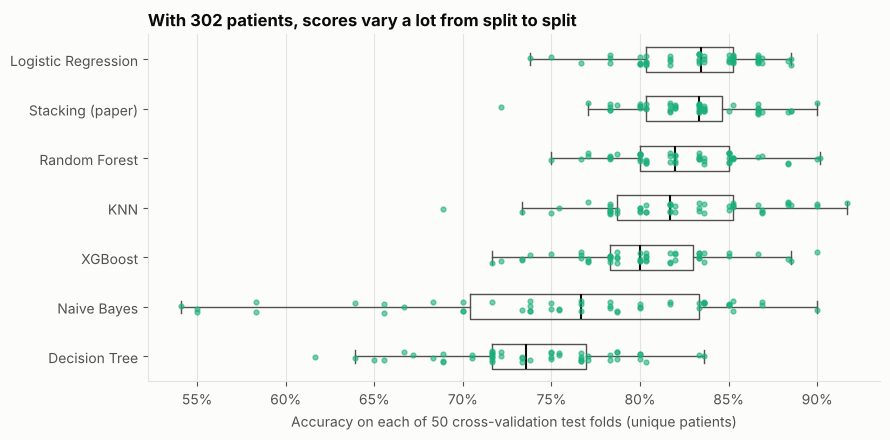

In [10]:
order = honest.index
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot([honest_runs[n] for n in order], orientation="horizontal", widths=0.5, showfliers=False,
           medianprops={"color": INK, "linewidth": 1.5},
           boxprops={"color": INK2}, whiskerprops={"color": INK2}, capprops={"color": INK2})
rng = np.random.default_rng(RS)
for i, n in enumerate(order, start=1):
    ax.scatter(honest_runs[n], i + rng.uniform(-0.12, 0.12, len(honest_runs[n])), s=12, color=HONEST, alpha=0.6, zorder=3)
ax.set_yticks(range(1, len(order) + 1), order)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Accuracy on each of 50 cross-validation test folds (unique patients)")
ax.set_title("With 302 patients, scores vary a lot from split to split", loc="left")
plt.tight_layout()
plt.savefig(f"{IMG}/cv_spread.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations**
- **Honest accuracy is about 82 to 83% for the best models, not 98.5%.** Logistic Regression (83.1%), stacking (82.8%), Random Forest (82.4%) and KNN (82.2%) are effectively tied.
- **Stacking doesn't beat its own simplest member.** Logistic Regression alone performs as well as the 6-model stack, with far less complexity.
- **The models the leak flattered most drop the furthest.** The Decision Tree goes from 98.5% (leaky) to 73.7%, and XGBoost from 100% to 80.1%.
- **Scores swing a lot between folds.** Even for the best models, accuracy on individual test folds ranges from the low 70s to about 90% (the box plot above). A single 80/20 split of 302 patients, lucky or unlucky, can't support claims to a decimal place.

## 5. Missing heart disease cases: the recall trade-off

In screening, a **missed case** (false negative) is far more costly than a false alarm, which leads to a follow-up test. Every model above uses a 0.5 probability threshold by default. Lowering it catches more cases at the cost of more false alarms.

This uses **out-of-fold probabilities** for Logistic Regression: every patient's probability comes from a model that never saw them. Logistic Regression is used because it's among the best honest performers and is easy to explain to clinicians.

In [11]:
lr_pipe = all_pipelines()["Logistic Regression"]
prob = cross_val_predict(lr_pipe, Xu, yu, cv=StratifiedKFold(5, shuffle=True, random_state=RS), method="predict_proba")[:, 1]

rows = []
for t in np.round(np.arange(0.20, 0.71, 0.05), 2):
    pred = (prob >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(yu, pred).ravel()
    rows.append({"threshold": t, "recall": tp_ / (tp_ + fn_), "specificity": tn_ / (tn_ + fp_),
                 "missed_cases": fn_, "false_alarms": fp_})
tradeoff = pd.DataFrame(rows)
print(f"{yu.sum()} patients with heart disease, {(yu == 0).sum()} without\n")
tradeoff.round(3)

164 patients with heart disease, 138 without



,threshold,recall,specificity,missed_cases,false_alarms
0,0.20,0.945,0.601,9,55
1,0.25,0.933,0.630,11,51
2,0.30,0.927,0.681,12,44
3,0.35,0.921,0.717,13,39
4,0.40,0.902,0.739,16,36
5,0.45,0.890,0.768,18,32
6,0.50,0.872,0.790,21,29
7,0.55,0.860,0.804,23,27
8,0.60,0.835,0.841,27,22
9,0.65,0.780,0.870,36,18


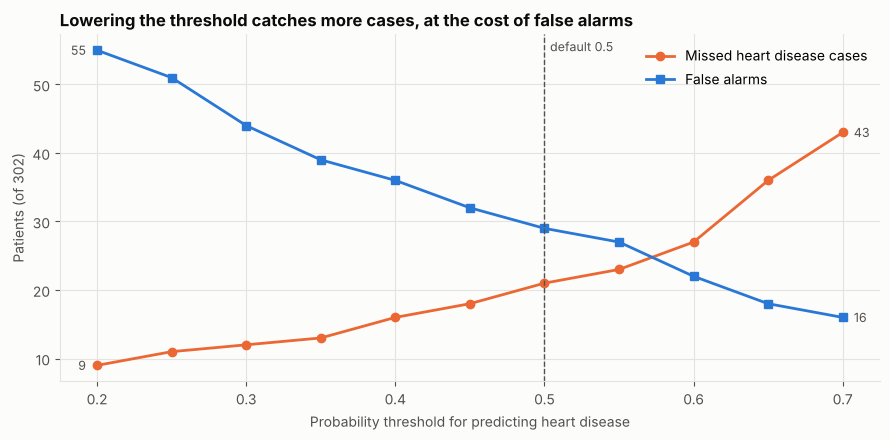

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(tradeoff["threshold"], tradeoff["missed_cases"], color=LEAKY, linewidth=2, marker="o", markersize=6, label="Missed heart disease cases")
ax.plot(tradeoff["threshold"], tradeoff["false_alarms"], color=PAPER, linewidth=2, marker="s", markersize=6, label="False alarms")
for col, colour in [("missed_cases", LEAKY), ("false_alarms", PAPER)]:
    last = tradeoff.iloc[-1]
    ax.annotate(f"{int(last[col])}", (last['threshold'], last[col]), xytext=(8, 0), textcoords="offset points", va="center", color=INK2, fontsize=9)
    first = tradeoff.iloc[0]
    ax.annotate(f"{int(first[col])}", (first['threshold'], first[col]), xytext=(-8, 0), textcoords="offset points", ha="right", va="center", color=INK2, fontsize=9)
ax.axvline(0.5, color=INK2, linewidth=1, linestyle="--")
ax.annotate("default 0.5", (0.5, ax.get_ylim()[1]), xytext=(4, -12), textcoords="offset points", color=INK2, fontsize=9)
ax.set_xlabel("Probability threshold for predicting heart disease")
ax.set_ylabel("Patients (of 302)")
ax.set_title("Lowering the threshold catches more cases, at the cost of false alarms", loc="left")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.savefig(f"{IMG}/threshold_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations**
- **At the default threshold of 0.5, Logistic Regression misses 21 of 164 heart disease cases** (87% recall), with 29 false alarms.
- **Lowering the threshold to 0.3 cuts missed cases to 12** (93% recall), but raises false alarms to 44.
- **Which threshold is right is a clinical decision, not a modelling one.** For a screening tool, catching more cases at the cost of extra follow-up tests is usually the better trade.

## 6. Conclusions

| Question | Answer |
|---|---|
| Can the paper's 98.53% be reproduced? | Yes, and even 100%, but only because 99% of the test patients are also in the training data |
| What's the honest accuracy? | About 82 to 83% for the best models (repeated 5-fold CV on 302 unique patients) |
| Does stacking help? | No. It ties with plain Logistic Regression |
| Which model would I recommend? | **Logistic Regression**: as accurate as anything else, as stable across folds as the ensembles, and easy to explain to clinicians |
| How should it be used? | With a lowered threshold (around 0.3) so fewer cases are missed, accepting more follow-up tests |

**The broader lesson:** before trusting any reported accuracy, check for duplicate records and how the data was split. Any near-perfect result reported on this Kaggle file deserves the same check.

## 7. Limitations
- **302 patients is small.** Even with repeated cross-validation, differences of 1 to 2 percentage points between models aren't meaningful.
- **Default hyperparameters.** Models weren't tuned, to keep the comparison with the paper fair. Tuning inside nested cross-validation might add a little, but can't fix the leakage.
- **Undocumented category codes.** A few patients have `ca = 4` or `thal = 0`, which aren't in the dataset documentation. They're kept as their own categories rather than guessed.
- **The paper's random seed is unknown**, so the reproduced numbers can't match it exactly.

## References
[1] M. Bhagat, A. Sharma and P. Agarwal, "An efficient stacking-based ensemble technique for early heart attack prediction," *Multimedia Tools and Applications*, 2024, doi: 10.1007/s11042-024-19293-7.

[2] A. Janosi, W. Steinbrunn, M. Pfisterer and R. Detrano, "Heart Disease," UCI Machine Learning Repository, 1988, doi: 10.24432/C52P4X.